In [9]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys
path = str(Path(Path('File.py').parent.absolute()).parent.absolute())
sys.path.insert(0, path)

path = str(Path(Path('thermo.py').parent.absolute()).parent.absolute())
sys.path.insert(0, path)

import numpy as np
import matplotlib as mlab
import matplotlib.pyplot as plt
import scipy
import xarray as xr
import os as os
import glob
import matplotlib.gridspec as gridspec
import tools
from tools.cbook import pickle2Obj, interp_z, compute_thetae
from tools.FV3_tools import read_solo_fields
from tools.CM1_tools import read_cm1_fields
import matplotlib.transforms as transforms

from pltbook import nice_clevels, nice_mxmnintvl, container, plot_contour_row

import matplotlib.colors as mcolors

cmap_data = [(1.0, 1.0, 1.0),
         (0.3137255012989044, 0.8156862854957581, 0.8156862854957581),
         (0.0, 1.0, 1.0),
         (0.0, 0.8784313797950745, 0.501960813999176),
         (0.0, 0.7529411911964417, 0.0),
         (0.501960813999176, 0.8784313797950745, 0.0),
         (1.0, 1.0, 0.0),
         (1.0, 0.6274510025978088, 0.0),
         (1.0, 0.0, 0.0),
         (1.0, 0.125490203499794, 0.501960813999176),
         (0.9411764740943909, 0.250980406999588, 1.0),
         (0.501960813999176, 0.125490203499794, 1.0),
         (0.250980406999588, 0.250980406999588, 1.0),
         (0.125490203499794, 0.125490203499794, 0.501960813999176),
         (0.125490203499794, 0.125490203499794, 0.125490203499794),
         (0.501960813999176, 0.501960813999176, 0.501960813999176),
         (0.8784313797950745, 0.8784313797950745, 0.8784313797950745),
         (0.9333333373069763, 0.8313725590705872, 0.7372549176216125),
         (0.8549019694328308, 0.6509804129600525, 0.47058823704719543),
         (0.6274510025978088, 0.42352941632270813, 0.23529411852359772),
         (0.4000000059604645, 0.20000000298023224, 0.0)]

# draw filled contours.
wclevs = [0, 1, 2.5, 5, 7.5, 10, 15, 20, 30, 40, 50, 60, 70]

tclevs = list(-40.0 + 2*np.arange(41))

teclevs = list(300. + 5*np.arange(70))

bclevs = list(-0.4+ 0.02*np.arange(100))
pclevs = list(-15.0 + np.arange(31))

dclevs = list(-20.0 + np.arange(41))

zlevels = 10.0 + 100.*np.arange(200)

def label_panels(axs, panel_labels, fontsize=14, adjust_loc=None):

    from operator import add

    base_loc = [0.025, 0.975]

    if adjust_loc:
        loc = list(map(add, base_loc, adjust_loc)) 
    else:
        loc = base_loc

    for i, ax in enumerate(axs.flatten()):
    # Add the panel label
        ax.text(*loc, panel_labels[i], transform=ax.transAxes, fontsize=fontsize, fontweight='medium', va='top', ha='left')

    return axs

def find_max_ijk(array):
    
    flat_max_index = np.argmax( array )
    return np.unravel_index(flat_max_index, array.shape)

linestyles = ['solid','--',':'] 

#=============================================================================
paths = {}
paths['cm1']     = '/work/wicker/climate_runs/cm1r20.3/run/bubble/3km/QV14'
#paths['cm1_w0']  = '/work/wicker/climate_runs/cm1r20.3/run/bubble_WW0/3km/QV14'
paths['solo']    = '/work/wicker/climate_runs/FV3_Solo/bubble/test_cond/3km/QV14'

models = {}
for key in paths:
    print("\n Reading: ",key)
    if key[0:3] == 'cm1':
        models[key] = ( read_cm1_fields(paths[key], vars = ['w', 'buoy', 'pert_p',  'qc'], zinterp=zlevels, ret_ds=False) )
    if key[0:4] == 'solo':
        models[key] = ( read_solo_fields(paths[key], vars = ['w', 'buoy', 'pert_p', 'qc'], zinterp=zlevels, ret_ds=False) )

savefigs = False

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload

 Reading:  cm1
------------------------------------------------------------------------------------------------------------------------

 Now reading... /work/wicker/climate_runs/cm1r20.3/run/bubble/3km/QV14/cm1out.nc

 Time for xarray to load:  /work/wicker/climate_runs/cm1r20.3/run/bubble/3km/QV14/cm1out.nc: 0.03 sec 

 Completed setup for:  /work/wicker/climate_runs/cm1r20.3/run/bubble/3km/QV14/cm1out.nc --> time to initialize variables: 0.66 sec 

 336.3203 -2923.421

 Completed reading in:  /work/wicker/climate_runs/cm1r20.3/run/bubble/3km/QV14/cm1out.nc --> time to process variables: 1.24 sec 

 Interpolating fields to single column z-grid: /work/wicker/climate_runs/cm1r20.3/run/bubble/3km/QV14/cm1out.nc 

 Interpolated completed, Total CPU:  /work/wicker/climate_runs/cm1r20.3/run/bubble/3km/QV14: 1.22 sec 

 Total time for processing file:  /work/wicker/climate_runs/cm1r20.3/run/bubble/3km/Q

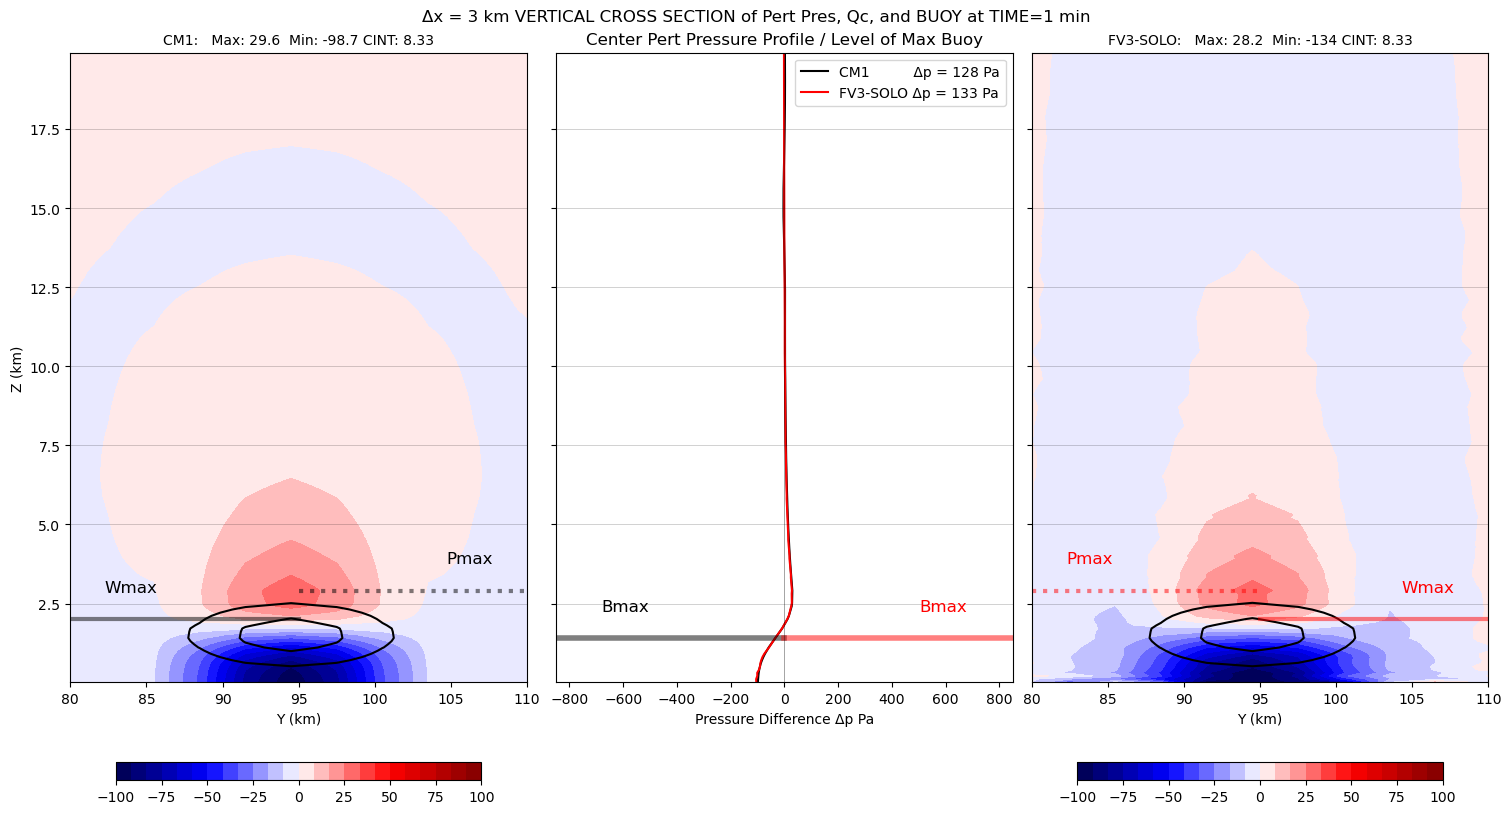

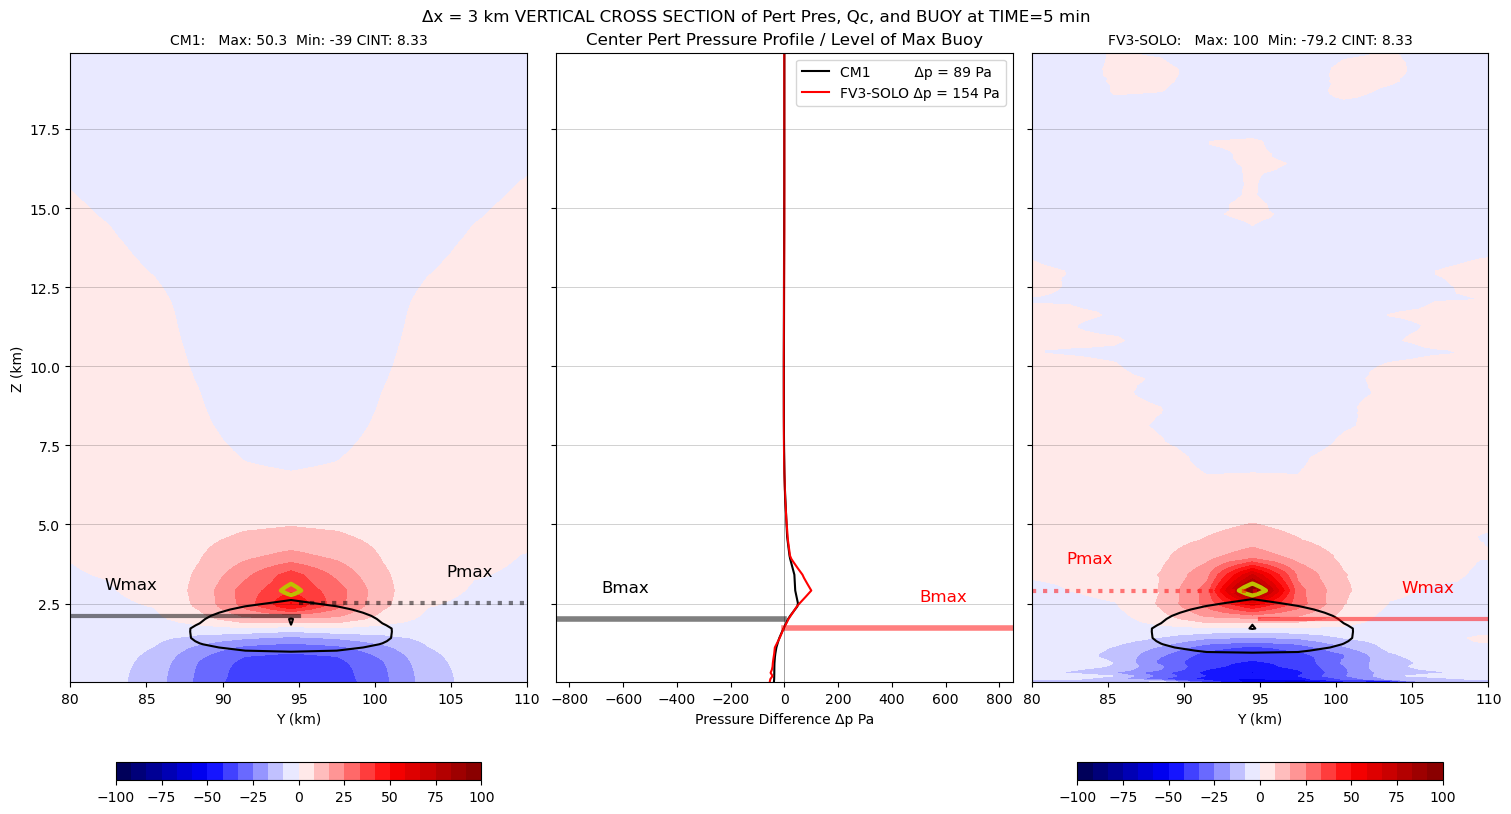

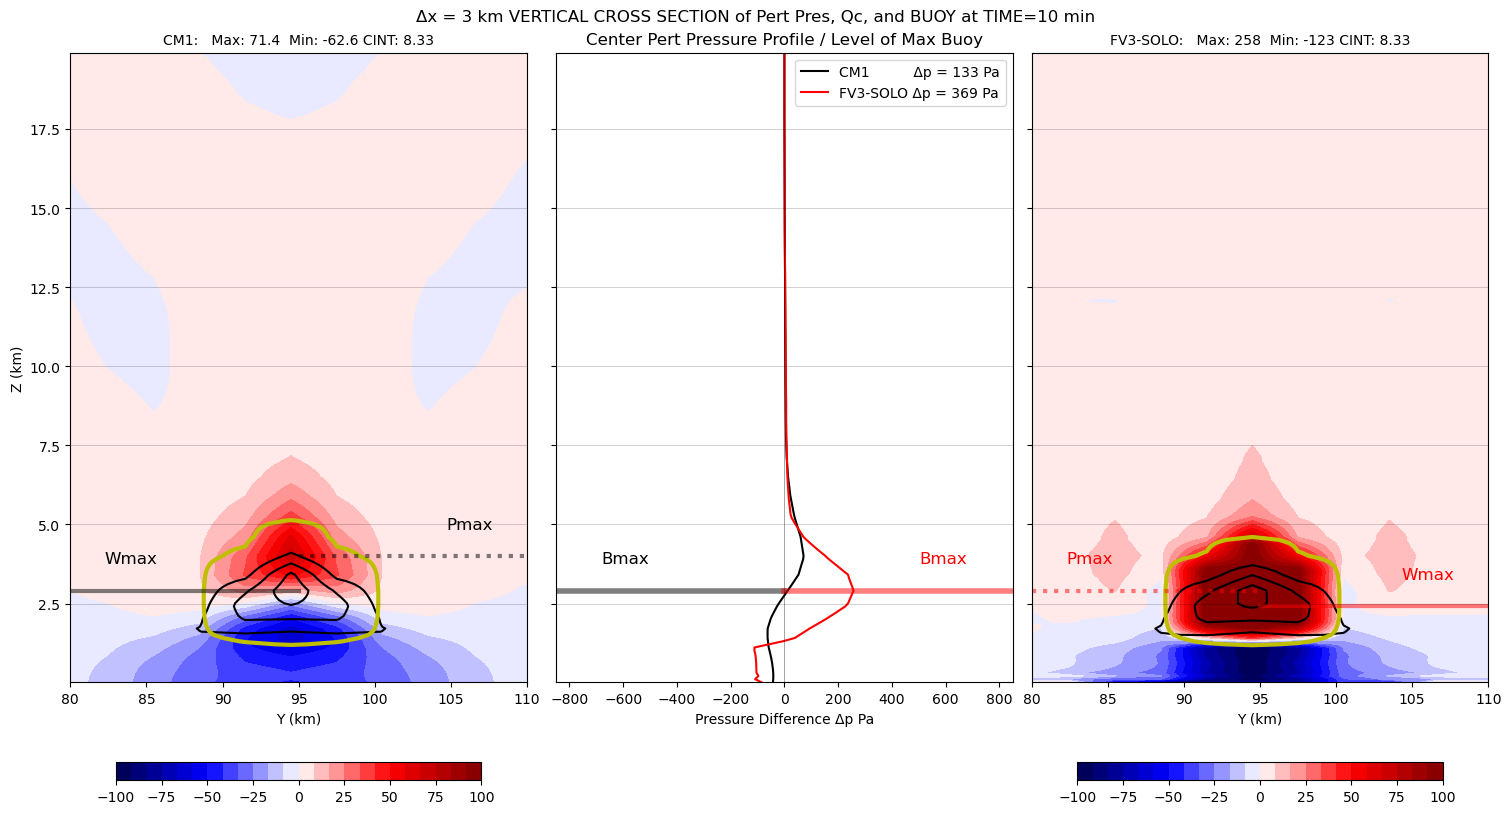

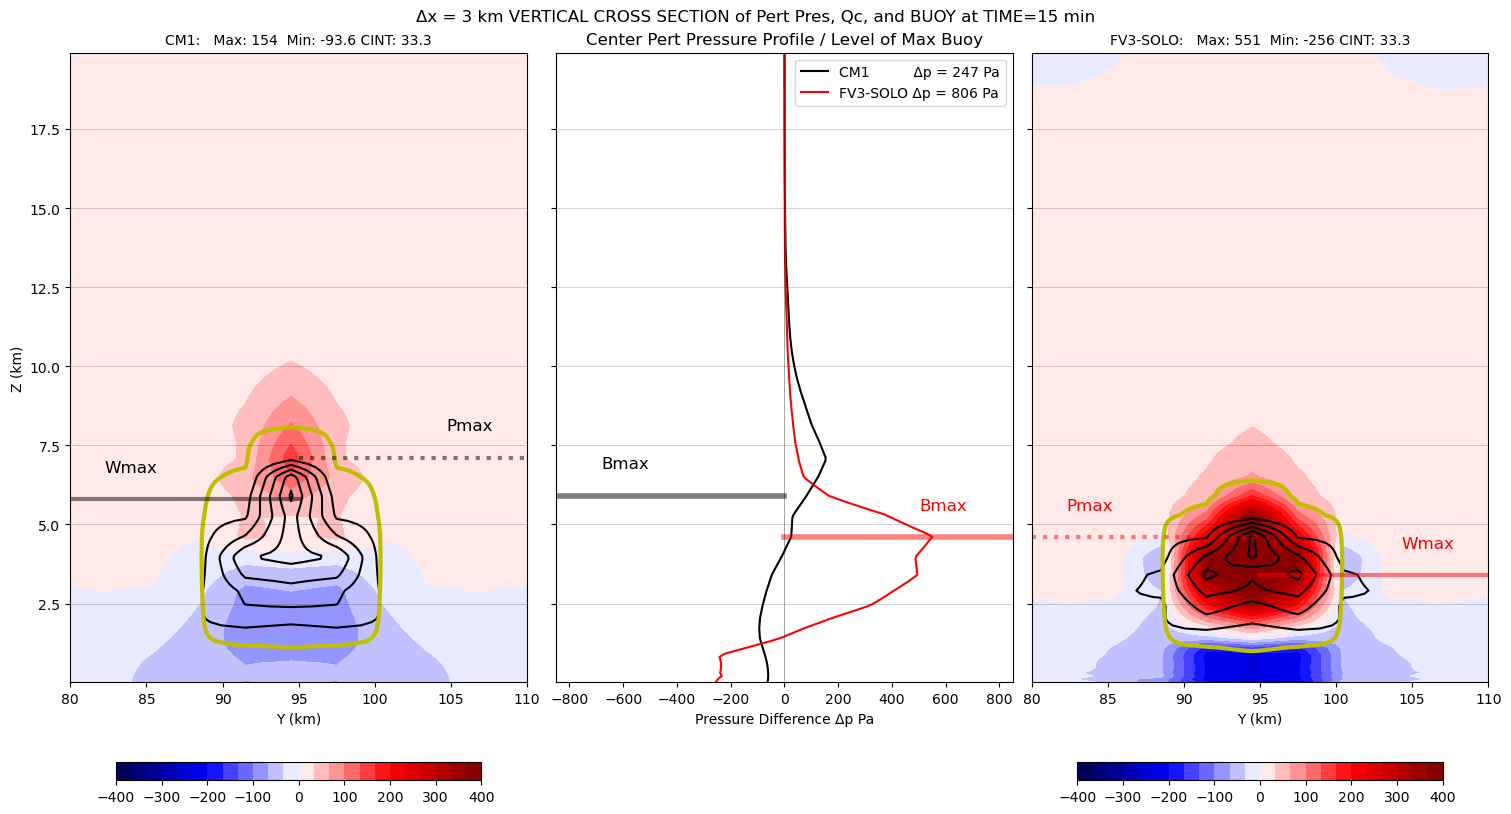

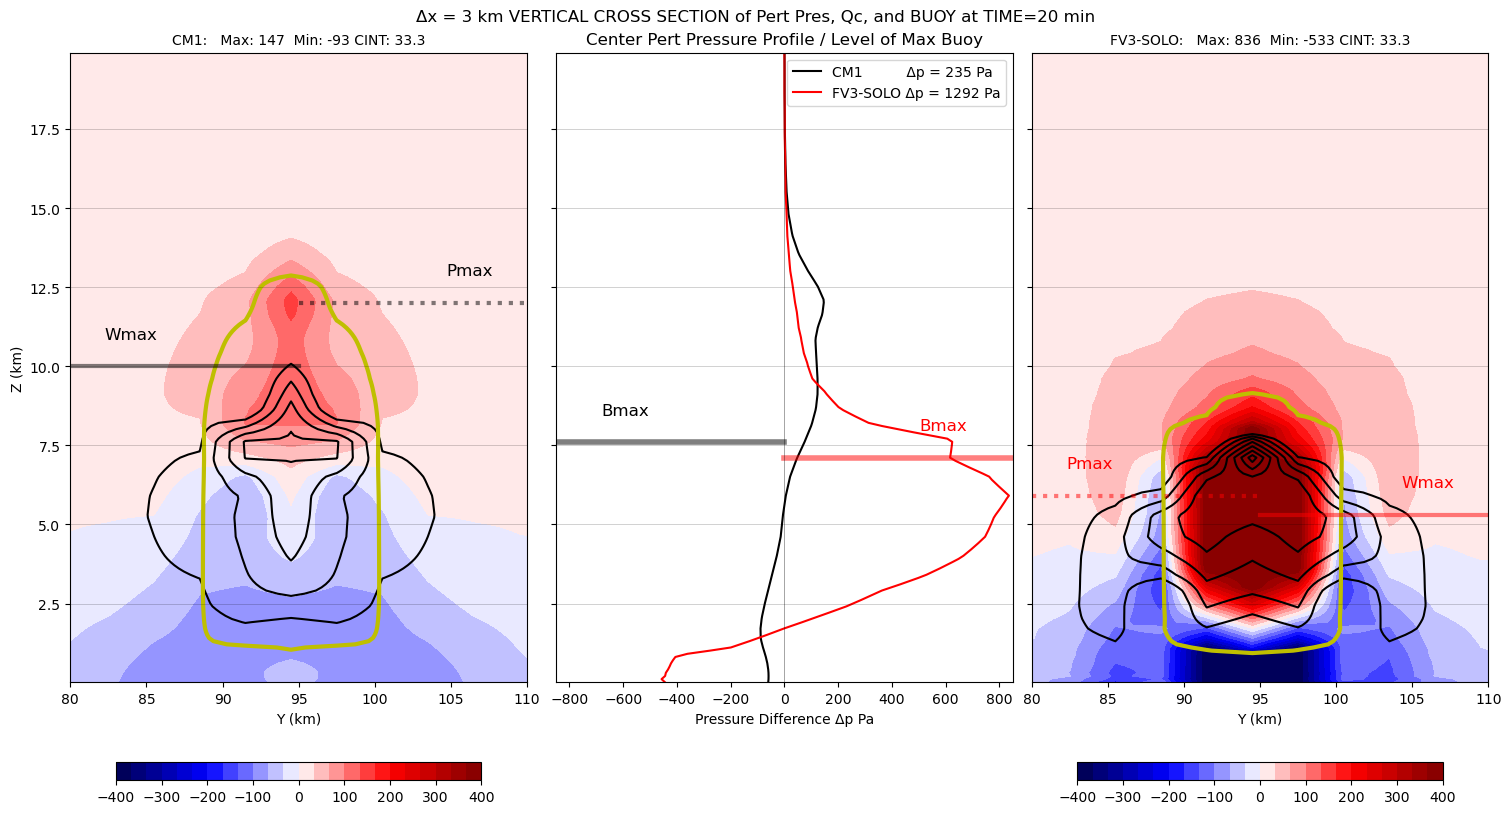

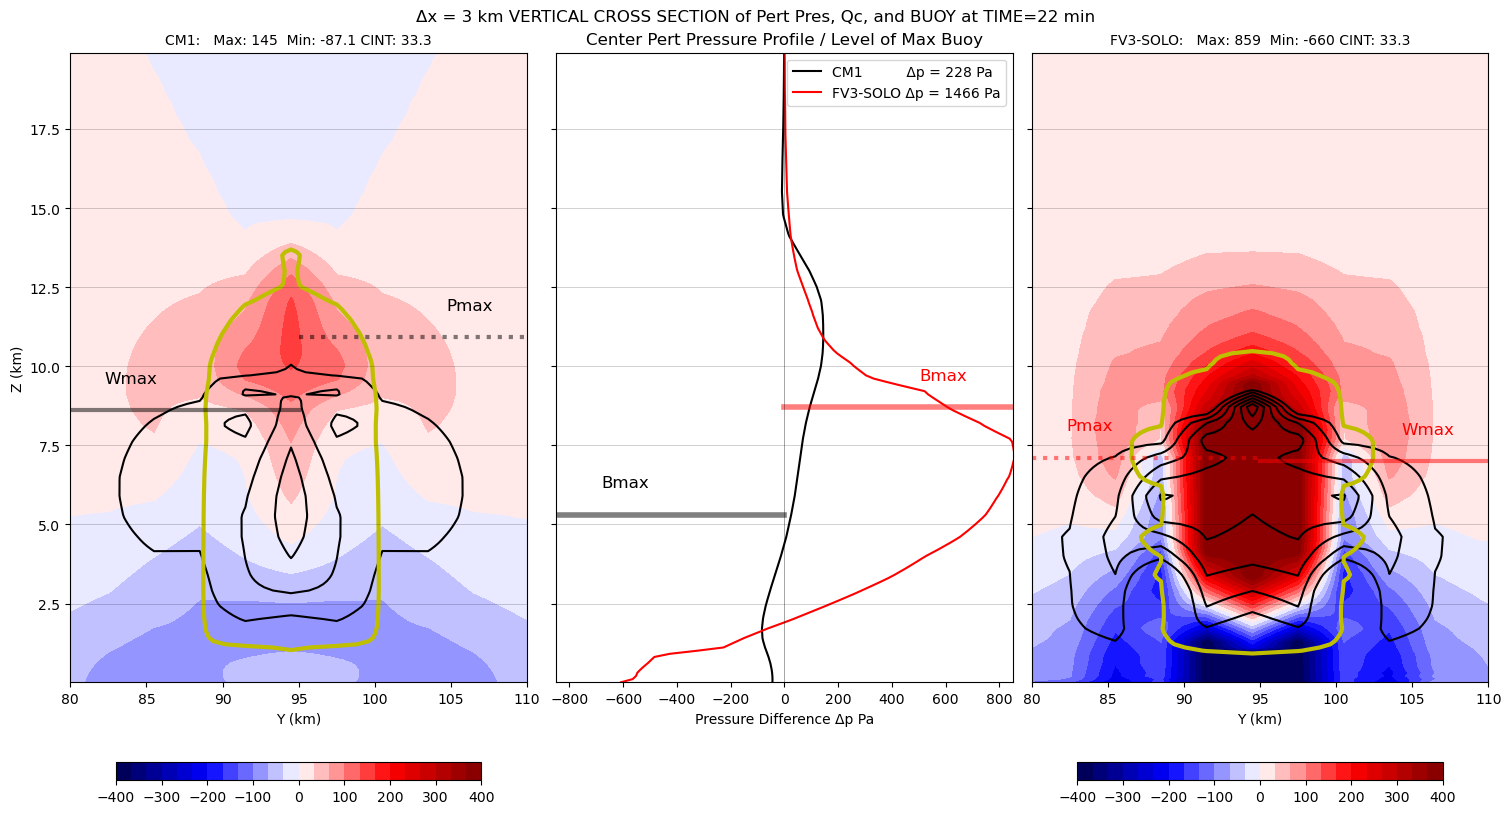

In [10]:
solo = models['solo']
cm1  = models['cm1']

time1 = solo['min'][:]
time2 = cm1['min'][:]
xc    = cm1['xc']/1000.
yc    = cm1['yc']/1000.

nx2 = (xc.shape[0]//2) - 1
ny2 = (yc.shape[0]//2) - 1

dp_unicode = "\u0394p"
linestyles = [':','--','solid'] 

for tlevel in [1, 5, 10, 15, 20, 22]:

    match tlevel:
        case 1:
             pclevs  = list(np.linspace(-100,100,25))
             pclevs2 = [x*1 for x in pclevs]
        case 5:
             pclevs  = list(np.linspace(-100,100,25))
             pclevs2 = [x*1 for x in pclevs]
        case 10:
             pclevs  = list(np.linspace(-100,100,25))
             pclevs2 = [x*1 for x in pclevs]
        case 15:
            pclevs  = list(np.linspace(-400,400,25))
            pclevs2 = [x*1 for x in pclevs]
        case 20:
            pclevs  = list(np.linspace(-400,400,25))
            pclevs2 = [x*1 for x in pclevs]
        case _:
            pclevs  = list(np.linspace(-400,400,25))
            pclevs2 = [x*1 for x in pclevs]

    pfield = 'pert_p3'

    ckmax, _, _ = find_max_ijk(cm1['w'][tlevel])
    skmax, _, _ = find_max_ijk(solo['w'][tlevel-1])

    fig, axes = plt.subplots(1, 3, sharey=True, constrained_layout=True, figsize=(15,8))

    pdiff_cm1 = int(cm1['pert_p'][tlevel, :,nx2,ny2].max() - cm1['pert_p'][tlevel, :,nx2,ny2].min())
    pdiff_sol = int(solo[pfield][tlevel-1, :,nx2,ny2].max() - solo[pfield][tlevel-1, :,nx2,ny2].min())

    axes[1].plot(cm1['pert_p'][tlevel, :,nx2,ny2], zlevels/1000., color='k', linestyle=linestyles[2],     label=f'CM1          {dp_unicode} = {pdiff_cm1} Pa')
    axes[1].plot(solo[pfield][tlevel-1,:,nx2,ny2], zlevels/1000., color='r', linestyle=linestyles[2],   label=f'FV3-SOLO {dp_unicode} = {pdiff_sol} Pa')
    axes[1].legend(loc='upper right', fontsize=10)
    axes[1].set_title(f"Center Pert Pressure Profile / Level of Max Buoy")
    axes[1].set_xlabel(f"Pressure Difference {dp_unicode} Pa")
    axes[1].set_xlim(-850,850)

    fields = []
    fields.append(container( cm1['pert_p'][tlevel,  :,:,ny2], yc, zlevels/1000.,   cint=pclevs, cmap=plt.cm.seismic))
    fields.append(container(solo[pfield][tlevel-1,:,:,ny2], yc, zlevels/1000.,   cint=pclevs2, cmap=plt.cm.seismic)) 

    plot_contour_row(fields, plot_type=2, ptitle=['CM1', 'FV3-SOLO'], suptitle=f"\u0394x = 3 km VERTICAL CROSS SECTION of Pert Pres, Qc, and BUOY at TIME={tlevel} min", 
                                 xlabel='X (km)', ylabel='Z (km)', xlim=[80.,110.], ax_in=[axes[0],axes[2]]);

# Plot buoy contours
    bclevs  = list(np.linspace(0.025,0.425,10))
    axes[0].contour(yc, zlevels/1000., cm1['buoy'][tlevel,  :,:,ny2], levels=bclevs,  colors=['k',], linewidths=[1.5,] )
    axes[2].contour(yc, zlevels/1000., solo['buoy'][tlevel-1,:,:,ny2], levels=bclevs, colors=['k',], linewidths=[1.5,] )
    axes[0].set_xlim(80.,110.)
    axes[2].set_xlim(80.,110.)
    axes[0].set_xlabel('Y (km)')
    axes[2].set_xlabel('Y (km)')

# Plot qc contours
    cclevs  = [0.1,]
    axes[0].contour(yc, zlevels/1000., cm1['qc'][tlevel,  :,:,ny2]*1000, levels=cclevs,  colors=['y',], linewidths=[3.0,] )
    axes[2].contour(yc, zlevels/1000., solo['qc'][tlevel-1,:,:,ny2]*1000., levels=cclevs, colors=['y',], linewidths=[3.0,] )
    axes[0].set_xlim(80.,110.)
    axes[2].set_xlim(80.,110.)

# Plot level of maximum buoy
    ckmax, _, _ = find_max_ijk(cm1['buoy'][tlevel])
    skmax, _, _ = find_max_ijk(solo['buoy'][tlevel-1])
    axes[1].axhline(y = zlevels[ckmax]/1000., xmin=0., xmax=0.5, color = 'k', alpha=0.5, linewidth=4.0 )
    axes[1].axhline(y = zlevels[skmax]/1000., xmin=0.5, xmax=1.0, color = 'r', alpha=0.5, linewidth=4.0 ) 
    axes[1].axvline(x = 0.0, color = 'k', alpha=0.5, linewidth=0.50 )
        # Add text info
    trans = transforms.blended_transform_factory(axes[1].transAxes, axes[1].transData)
    axes[1].text(0.1, 1 + zlevels[ckmax]/1000., "Bmax", transform=trans, fontsize=12,  color='k', verticalalignment='center', horizontalalignment='left')
    axes[1].text(0.9, 1 + zlevels[skmax]/1000., "Bmax", transform=trans, fontsize=12, color='r', verticalalignment='center', horizontalalignment='right')

# Plot level of maximum pert_p
    # max p label
    ckmax, _, _ = find_max_ijk(cm1['pert_p'][tlevel])
    skmax, _, _ = find_max_ijk(solo[pfield][tlevel-1])
    axes[0].axhline(y = zlevels[ckmax]/1000., xmin=0.5, xmax=1.0, color = 'k', alpha=0.5, linestyle=linestyles[0], linewidth=3.0 )
    axes[2].axhline(y = zlevels[skmax]/1000., xmin=0.0, xmax=0.5, color = 'r', alpha=0.5, linestyle=linestyles[0], linewidth=3.0 )
    trans = transforms.blended_transform_factory(axes[0].transAxes, axes[0].transData)
    axes[0].text(0.925, 1 + zlevels[ckmax]/1000., "Pmax", transform=trans, fontsize=12,  color='k', verticalalignment='center', horizontalalignment='right')
    trans = transforms.blended_transform_factory(axes[2].transAxes, axes[2].transData)
    axes[2].text(0.075, 1 + zlevels[skmax]/1000., "Pmax", transform=trans, fontsize=12, color='r', verticalalignment='center', horizontalalignment='left')

# Plot level of maximum w 
    ckmax, _, _ = find_max_ijk(cm1['w'][tlevel])
    skmax, _, _ = find_max_ijk(solo['w'][tlevel-1])
    axes[0].axhline(y = zlevels[ckmax]/1000., xmin=0., xmax=0.5, color = 'k', alpha=0.5, linestyle=linestyles[2], linewidth=3.0 )
    axes[2].axhline(y = zlevels[skmax]/1000., xmin=0.5, xmax=1.0, color = 'r', alpha=0.5, linestyle=linestyles[2], linewidth=3.0 )
    trans = transforms.blended_transform_factory(axes[0].transAxes, axes[0].transData)
    axes[0].text(0.075, 1 + zlevels[ckmax]/1000., "Wmax", transform=trans, fontsize=12,  color='k', verticalalignment='center', horizontalalignment='left')
    trans = transforms.blended_transform_factory(axes[2].transAxes, axes[2].transData)
    axes[2].text(0.925, 1 + zlevels[skmax]/1000., "Wmax", transform=trans, fontsize=12, color='r', verticalalignment='center', horizontalalignment='right')

# other lines of interest
    for hgt in [2.5, 5.0, 7.5, 10., 12.5, 15.0, 17.5]:
        axes[0].axhline(y = hgt, color = 'k', alpha=0.25, linestyle=linestyles[2], linewidth=0.5 )
        axes[1].axhline(y = hgt, color = 'k', alpha=0.25, linestyle=linestyles[2], linewidth=0.5 )
        axes[2].axhline(y = hgt, color = 'k', alpha=0.25, linestyle=linestyles[2], linewidth=0.5 )
    
    axes[0].set_ylabel('Z (km)', fontsize=10);
    # label_panels(axes, ['(a)', '(b)', '(c)'], fontsize=18)

    if savefigs: 
        plt.savefig("../Figures/Bubble_XZ_PertP_Buoy_QC_3km_TIME_%2.2d_min.pdf" % tlevel)

AttributeError: 'dict' object has no attribute 'dims'